# FocusLens Research: Short-Form Video Habits and Human Attention
### دراسة توعوية عن انتباه البشر وتأثير الفيديوهات القصيرة (Reels / Shorts / TikTok)

**Research question:** Is there a measurable relationship between digital habits (screen time,
social media hours, notifications) and human attention / cognitive performance?

**Note on data:** These datasets don't log TikTok/Reels usage directly, so `social_media_hours`,
`daily_screen_time_hours`, `app_opens_per_day`, and `notifications_per_day` are used as proxies
for short-form video consumption.

**Important:** This notebook is exploratory/statistical (EDA + correlation + hypothesis testing).
No predictive models are trained — the goal is awareness, not prediction.

### Libraries

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr, ttest_ind, mannwhitneyu, f_oneway, kruskal

### Figure Settings

In [2]:
os.makedirs("figures", exist_ok=True)

plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.bbox"] = "tight"

### Load Datasets

In [3]:
data_path = r"D:\FocusLens AI\Datasets"

human_df = pd.read_csv(
    os.path.join(data_path, "human_cognitive_performance.csv")
)

mobile_df = pd.read_excel(
    os.path.join(data_path, "Mobile_Usage_Screentime_Dataset_.xlsx")
)

phone_df = pd.read_csv(
    os.path.join(data_path, "Smartphone_Usage_And_Addiction_Analysis_7500_Rows.csv")
)

In [4]:
print("Human Cognitive:", human_df.shape)
print("Mobile Usage:", mobile_df.shape)
print("Smartphone Addiction:", phone_df.shape)

Human Cognitive: (80000, 13)
Mobile Usage: (120, 12)
Smartphone Addiction: (7500, 16)


### Step1: Initial Inspection

In [5]:
print(human_df.info())
print(human_df.describe())
print(human_df.isnull().sum())
print(human_df.head())

<class 'pandas.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   User_ID             80000 non-null  str    
 1   Age                 80000 non-null  int64  
 2   Gender              80000 non-null  str    
 3   Sleep_Duration      80000 non-null  float64
 4   Stress_Level        80000 non-null  int64  
 5   Diet_Type           80000 non-null  str    
 6   Daily_Screen_Time   80000 non-null  float64
 7   Exercise_Frequency  80000 non-null  str    
 8   Caffeine_Intake     80000 non-null  int64  
 9   Reaction_Time       80000 non-null  float64
 10  Memory_Test_Score   80000 non-null  int64  
 11  Cognitive_Score     80000 non-null  float64
 12  AI_Predicted_Score  80000 non-null  float64
dtypes: float64(5), int64(4), str(4)
memory usage: 7.9 MB
None
                Age  Sleep_Duration  Stress_Level  Daily_Screen_Time  \
count  80000.000000    80000.000

In [6]:
print(mobile_df.info())
print(mobile_df.describe())
print(mobile_df.isnull().sum())
print(mobile_df.head())

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   UserID                  120 non-null    int64  
 1   Age                     120 non-null    int64  
 2   Gender                  120 non-null    str    
 3   Daily_ScreenTime_Hours  120 non-null    float64
 4   SocialMedia_Min         120 non-null    int64  
 5   Gaming_Min              120 non-null    int64  
 6   Study_Min               120 non-null    int64  
 7   Sleep_Hours             120 non-null    float64
 8   Device Type             120 non-null    str    
 9   Calls_Min               120 non-null    int64  
 10  Messages_Sent           120 non-null    int64  
 11  Battery_Drain_Percent   120 non-null    int64  
dtypes: float64(2), int64(8), str(2)
memory usage: 11.4 KB
None
           UserID         Age  Daily_ScreenTime_Hours  SocialMedia_Min  \
count  120.000000  120.000

In [7]:
print(phone_df.info())
print(phone_df.describe())
print(phone_df.isnull().sum())
print(phone_df.head())

<class 'pandas.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   transaction_id           7500 non-null   str    
 1   user_id                  7500 non-null   str    
 2   age                      7500 non-null   int64  
 3   gender                   7500 non-null   str    
 4   daily_screen_time_hours  7500 non-null   float64
 5   social_media_hours       7500 non-null   float64
 6   gaming_hours             7500 non-null   float64
 7   work_study_hours         7500 non-null   float64
 8   sleep_hours              7500 non-null   float64
 9   notifications_per_day    7500 non-null   int64  
 10  app_opens_per_day        7500 non-null   int64  
 11  weekend_screen_time      7500 non-null   float64
 12  stress_level             7500 non-null   str    
 13  academic_work_impact     7500 non-null   str    
 14  addiction_level          6681 non-n

### Step2: Cleaning + Feature Engineering

In [8]:
human_clean = human_df.copy()
phone_clean = phone_df.copy()
mobile_clean = mobile_df.copy()

# drop unnecessary columns
human_clean.drop(
    columns=[
        "User_ID",
        "AI_Predicted_Score"
    ],
    inplace=True
)

phone_clean.drop(
    columns=[
        "transaction_id",
        "user_id"
    ],
    inplace=True
)

In [9]:
print("Human missing values:")
print(human_clean.isnull().sum())

print("\nPhone missing values:")
print(phone_clean.isnull().sum())

phone_clean["addiction_level"] = phone_clean["addiction_level"].fillna("Unknown")

Human missing values:
Age                   0
Gender                0
Sleep_Duration        0
Stress_Level          0
Diet_Type             0
Daily_Screen_Time     0
Exercise_Frequency    0
Caffeine_Intake       0
Reaction_Time         0
Memory_Test_Score     0
Cognitive_Score       0
dtype: int64

Phone missing values:
age                          0
gender                       0
daily_screen_time_hours      0
social_media_hours           0
gaming_hours                 0
work_study_hours             0
sleep_hours                  0
notifications_per_day        0
app_opens_per_day            0
weekend_screen_time          0
stress_level                 0
academic_work_impact         0
addiction_level            819
addicted_label               0
dtype: int64


In [10]:
# Digital habit indicators (descriptive, not model features)

phone_clean["Switching_Cost_Seconds"] = (
    phone_clean["notifications_per_day"] * 25
)

phone_clean["Switching_Cost_Minutes"] = (
    phone_clean["Switching_Cost_Seconds"] / 60
)

phone_clean["Digital_Load_Index"] = (
    phone_clean["daily_screen_time_hours"]
    +
    phone_clean["social_media_hours"]
    +
    phone_clean["gaming_hours"]
)

phone_clean["Sleep_Deficit"] = (
    8 - phone_clean["sleep_hours"]
).clip(lower=0)

In [11]:
print("Human duplicates:", human_clean.duplicated().sum())
print("Phone duplicates:", phone_clean.duplicated().sum())

human_clean.drop_duplicates(inplace=True)
phone_clean.drop_duplicates(inplace=True)

print("\nHuman dataset:", human_clean.shape)
print("Phone dataset:", phone_clean.shape)

Human duplicates: 0
Phone duplicates: 0

Human dataset: (80000, 11)
Phone dataset: (7500, 18)


### Step2b: Data Realism Check

In [12]:
# if a variable is drawn from a uniform distribution, its SD is close to
# (max - min) / sqrt(12)   (for integer columns: sqrt((k^2 - 1) / 12), k = number of values)

check_cols = {
    "human": ["Age", "Sleep_Duration", "Stress_Level", "Daily_Screen_Time",
              "Caffeine_Intake", "Reaction_Time", "Memory_Test_Score"],
    "phone": ["age", "daily_screen_time_hours", "social_media_hours", "gaming_hours",
              "work_study_hours", "sleep_hours", "notifications_per_day", "app_opens_per_day"]
}

rows = []

for name, cols in check_cols.items():
    df = human_clean if name == "human" else phone_clean

    for col in cols:
        observed_sd = df[col].std()

        if pd.api.types.is_integer_dtype(df[col]):
            k = df[col].max() - df[col].min() + 1
            expected_sd = np.sqrt((k ** 2 - 1) / 12)
        else:
            expected_sd = (df[col].max() - df[col].min()) / np.sqrt(12)

        rows.append([name, col, observed_sd, expected_sd, observed_sd / expected_sd])

uniform_check = pd.DataFrame(
    rows,
    columns=["dataset", "variable", "observed_sd", "uniform_expected_sd", "ratio"]
)

print(uniform_check.round(3))

   dataset                 variable  observed_sd  uniform_expected_sd  ratio
0    human                      Age       12.102               12.121  0.998
1    human           Sleep_Duration        1.734                1.732  1.001
2    human             Stress_Level        2.865                2.872  0.998
3    human        Daily_Screen_Time        3.167                3.175  0.997
4    human          Caffeine_Intake      144.542              144.337  1.001
5    human            Reaction_Time      115.369              115.467  0.999
6    human        Memory_Test_Score       17.306               17.318  0.999
7    phone                      age        5.197                5.188  1.002
8    phone  daily_screen_time_hours        2.609                2.598  1.004
9    phone       social_media_hours        1.585                1.588  0.999
10   phone             gaming_hours        1.146                1.155  0.992
11   phone         work_study_hours        1.601                1.588  1.008

In [13]:
# internal consistency: the parts of the day should not exceed total screen time

parts = (
    phone_clean["social_media_hours"]
    + phone_clean["gaming_hours"]
    + phone_clean["work_study_hours"]
)

share_inconsistent = (parts > phone_clean["daily_screen_time_hours"]).mean()

print("Rows where social + gaming + work/study hours exceed total screen time:",
      round(share_inconsistent * 100, 1), "%")

print("Correlation (screen time vs social media hours):",
      round(phone_clean["daily_screen_time_hours"].corr(phone_clean["social_media_hours"]), 3))

Rows where social + gaming + work/study hours exceed total screen time: 60.7 %
Correlation (screen time vs social media hours): 0.01


### Step3: Descriptive Statistics — Digital Habits & Attention

In [14]:
print("Cognitive Score summary:")
print(human_clean["Cognitive_Score"].describe())

print("\nDaily Screen Time summary (human dataset):")
print(human_clean["Daily_Screen_Time"].describe())

Cognitive Score summary:
count    80000.000000
mean        58.172395
std         23.058522
min          0.000000
25%         40.910000
50%         58.360000
75%         75.830000
max        100.000000
Name: Cognitive_Score, dtype: float64

Daily Screen Time summary (human dataset):
count    80000.000000
mean         6.504646
std          3.167072
min          1.000000
25%          3.800000
50%          6.500000
75%          9.200000
max         12.000000
Name: Daily_Screen_Time, dtype: float64


In [15]:
print("Social media hours summary (phone dataset):")
print(phone_clean["social_media_hours"].describe())

print("\nAddiction label distribution:")
print(phone_clean["addicted_label"].value_counts(normalize=True))

Social media hours summary (phone dataset):
count    7500.000000
mean        3.273484
std         1.585342
min         0.500000
25%         1.910000
50%         3.270000
75%         4.630000
max         6.000000
Name: social_media_hours, dtype: float64

Addiction label distribution:
addicted_label
1    0.707733
0    0.292267
Name: proportion, dtype: float64


### Distributions of Key Variables

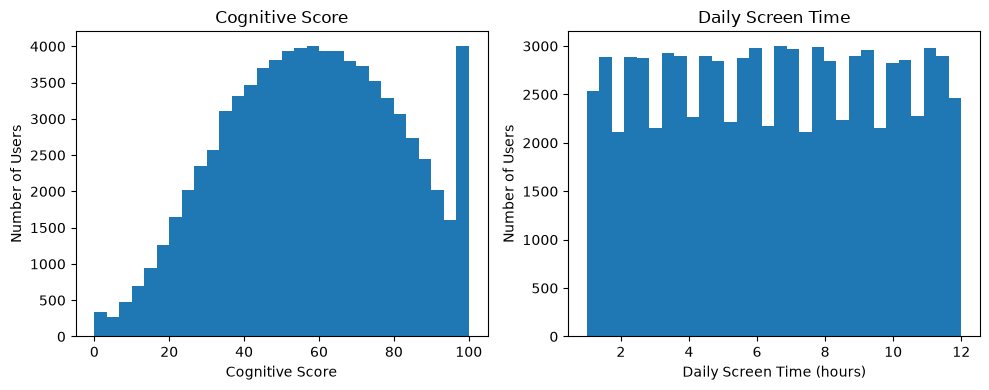

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(human_clean["Cognitive_Score"], bins=30)
axes[0].set_title("Cognitive Score")
axes[0].set_xlabel("Cognitive Score")
axes[0].set_ylabel("Number of Users")

axes[1].hist(human_clean["Daily_Screen_Time"], bins=30)
axes[1].set_title("Daily Screen Time")
axes[1].set_xlabel("Daily Screen Time (hours)")
axes[1].set_ylabel("Number of Users")

plt.tight_layout()
plt.savefig("figures/fig01_distributions.png")
plt.show()

### Correlation: Screen Time vs Cognitive Performance

In [17]:
corr = human_clean.corr(numeric_only=True)

print(corr["Cognitive_Score"].sort_values(ascending=False))

Cognitive_Score      1.000000
Memory_Test_Score    0.363894
Sleep_Duration       0.150595
Age                 -0.005976
Caffeine_Intake     -0.122862
Daily_Screen_Time   -0.198515
Stress_Level        -0.227639
Reaction_Time       -0.818470
Name: Cognitive_Score, dtype: float64


In [18]:
r_value, p_value = pearsonr(
    human_clean["Daily_Screen_Time"],
    human_clean["Cognitive_Score"]
)

print("Pearson r:", r_value)
print("p-value:", p_value)

Pearson r: -0.19851549072584493
p-value: 0.0


### Effect Size and Robustness: Screen Time vs Cognitive Score

In [19]:
# 95% confidence interval for r (Fisher z-transform)
n_human = len(human_clean)

z = np.arctanh(r_value)
se = 1 / np.sqrt(n_human - 3)

ci_low = np.tanh(z - 1.96 * se)
ci_high = np.tanh(z + 1.96 * se)

print("95% CI for r:", ci_low, ci_high)
print("r squared (share of variance explained):", r_value ** 2)

rho, rho_pvalue = spearmanr(
    human_clean["Daily_Screen_Time"],
    human_clean["Cognitive_Score"]
)

print("\nSpearman rho:", rho)
print("p-value:", rho_pvalue)

95% CI for r: -0.20516292464692729 -0.1918497425798976
r squared (share of variance explained): 0.03940840005812302

Spearman rho: -0.19011587605468724
p-value: 0.0


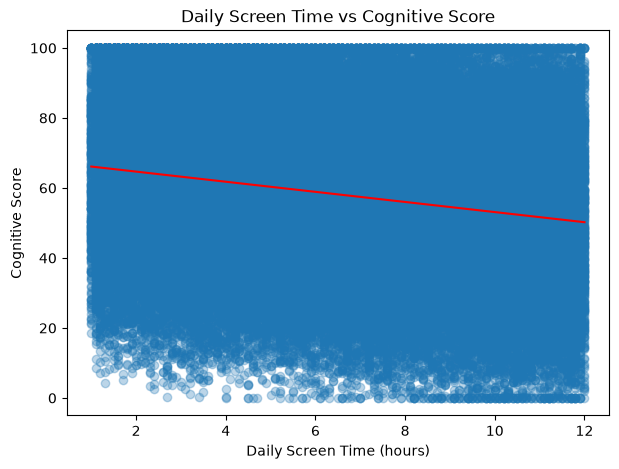

In [20]:
plt.figure(figsize=(7, 5))

plt.scatter(
    human_clean["Daily_Screen_Time"],
    human_clean["Cognitive_Score"],
    alpha=0.3
)

trend = np.polyfit(
    human_clean["Daily_Screen_Time"],
    human_clean["Cognitive_Score"],
    1
)

trend_line = np.poly1d(trend)

x_range = np.linspace(
    human_clean["Daily_Screen_Time"].min(),
    human_clean["Daily_Screen_Time"].max(),
    100
)

plt.plot(x_range, trend_line(x_range), color="red")

plt.title("Daily Screen Time vs Cognitive Score")
plt.xlabel("Daily Screen Time (hours)")
plt.ylabel("Cognitive Score")

plt.savefig("figures/fig04_scatter_screen_cognitive.png")
plt.show()

### Mean Cognitive Score by Screen Time Bin

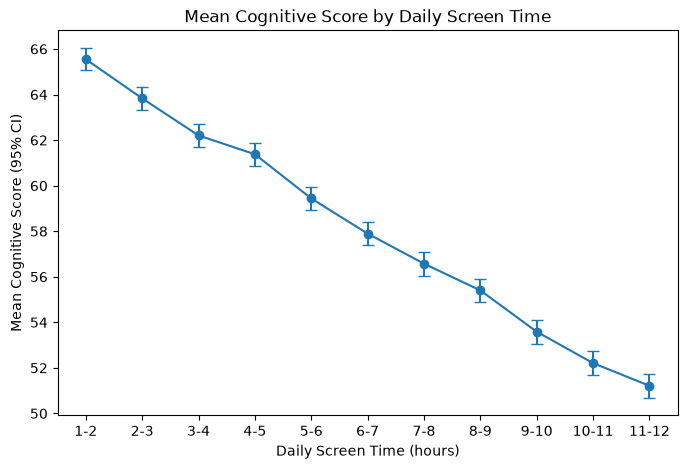

In [21]:
screen_bins = pd.cut(
    human_clean["Daily_Screen_Time"],
    bins=np.arange(1, 13, 1),
    include_lowest=True
)

binned = human_clean.groupby(screen_bins, observed=True)["Cognitive_Score"].agg(["mean", "std", "count"])
binned["ci95"] = 1.96 * binned["std"] / np.sqrt(binned["count"])

bin_labels = [f"{round(i.left)}-{round(i.right)}" for i in binned.index]

plt.figure(figsize=(8, 5))

plt.errorbar(
    range(len(binned)),
    binned["mean"],
    yerr=binned["ci95"],
    fmt="o-",
    capsize=4
)

plt.xticks(range(len(binned)), bin_labels)

plt.title("Mean Cognitive Score by Daily Screen Time")
plt.xlabel("Daily Screen Time (hours)")
plt.ylabel("Mean Cognitive Score (95% CI)")

plt.savefig("figures/fig05_binned_means.png")
plt.show()

### Correlation Heatmap (Human Cognitive Dataset)

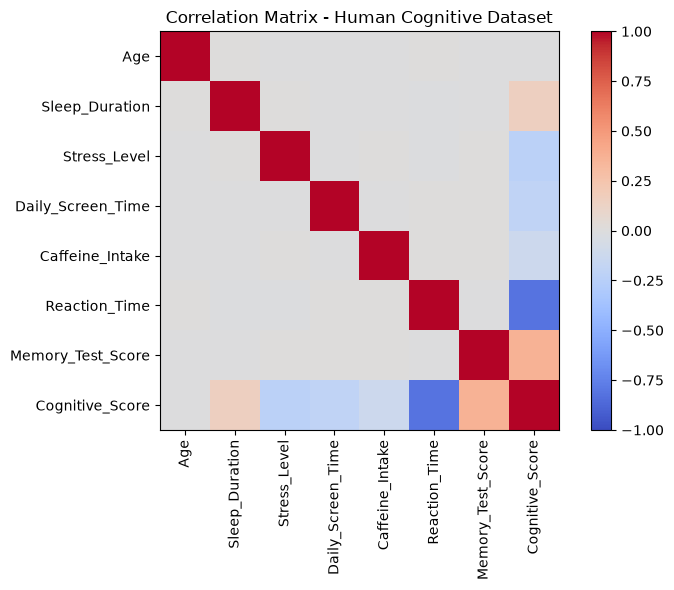

In [22]:
numeric_human = human_clean.select_dtypes(include=[np.number])

corr_matrix = numeric_human.corr()

plt.figure(figsize=(8, 6))

plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()

plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

plt.title("Correlation Matrix - Human Cognitive Dataset")

plt.tight_layout()
plt.savefig("figures/fig03_corr_heatmap.png")
plt.show()

### Correlation of Each Variable with Cognitive Score

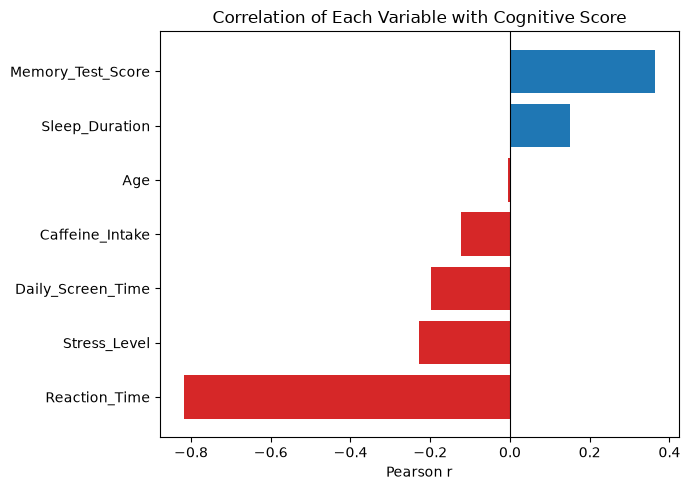

In [23]:
cog_corr = corr["Cognitive_Score"].drop("Cognitive_Score").sort_values()

plt.figure(figsize=(7, 5))

plt.barh(
    cog_corr.index,
    cog_corr.values,
    color=["tab:red" if v < 0 else "tab:blue" for v in cog_corr.values]
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Correlation of Each Variable with Cognitive Score")
plt.xlabel("Pearson r")

plt.tight_layout()
plt.savefig("figures/fig02_corr_bar.png")
plt.show()

### High vs Low Screen-Time Group Comparison

In [24]:
screen_median = human_clean["Daily_Screen_Time"].median()

low_group = human_clean[human_clean["Daily_Screen_Time"] <= screen_median]["Cognitive_Score"]
high_group = human_clean[human_clean["Daily_Screen_Time"] > screen_median]["Cognitive_Score"]

print("Low screen-time group mean Cognitive Score:", low_group.mean())
print("High screen-time group mean Cognitive Score:", high_group.mean())

Low screen-time group mean Cognitive Score: 62.1350338634052
High screen-time group mean Cognitive Score: 54.148056486357106


In [25]:
t_stat_screen, t_pvalue_screen = ttest_ind(low_group, high_group, equal_var=False)

print("t-statistic:", t_stat_screen)
print("p-value:", t_pvalue_screen)

t-statistic: 49.72551392951151
p-value: 0.0


### Effect Size and Robustness: Low vs High Screen Time

In [26]:
def cohens_d(a, b):
    pooled_sd = np.sqrt(
        ((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2)
    )
    return (a.mean() - b.mean()) / pooled_sd

d_screen = cohens_d(low_group, high_group)

print("Group sizes:", len(low_group), len(high_group))
print("Cohen's d (low vs high screen time):", d_screen)

u_stat, u_pvalue = mannwhitneyu(low_group, high_group, alternative="two-sided")

print("\nMann-Whitney U:", u_stat)
print("p-value:", u_pvalue)

Group sizes: 40309 39691
Cohen's d (low vs high screen time): 0.351690681124186

Mann-Whitney U: 952858215.5
p-value: 0.0


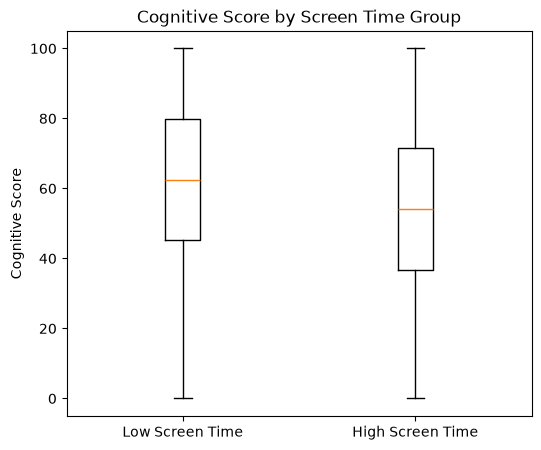

In [27]:
plt.figure(figsize=(6, 5))

plt.boxplot(
    [low_group, high_group],
    tick_labels=["Low Screen Time", "High Screen Time"]
)

plt.title("Cognitive Score by Screen Time Group")
plt.ylabel("Cognitive Score")

plt.savefig("figures/fig06_boxplot_groups.png")
plt.show()

### Social Media Usage vs Smartphone Addiction (Phone Dataset)

In [28]:
addiction_group_means = phone_clean.groupby("addicted_label")[
    [
        "social_media_hours",
        "daily_screen_time_hours",
        "sleep_hours",
        "notifications_per_day"
    ]
].mean()

print(addiction_group_means)

                social_media_hours  daily_screen_time_hours  sleep_hours  \
addicted_label                                                             
0                         2.251615                 5.156861     6.666665   
1                         3.695477                 8.467502     6.766839   

                notifications_per_day  
addicted_label                         
0                          134.325730  
1                          134.229088  


In [29]:
addicted_hours = phone_clean[phone_clean["addicted_label"] == 1]["social_media_hours"]
not_addicted_hours = phone_clean[phone_clean["addicted_label"] == 0]["social_media_hours"]

t_stat_addicted, t_pvalue_addicted = ttest_ind(addicted_hours, not_addicted_hours, equal_var=False)

print("Addicted group mean social media hours:", addicted_hours.mean())
print("Non-addicted group mean social media hours:", not_addicted_hours.mean())
print("t-statistic:", t_stat_addicted)
print("p-value:", t_pvalue_addicted)

Addicted group mean social media hours: 3.695476639035419
Non-addicted group mean social media hours: 2.2516149635036498
t-statistic: 46.876748193199845
p-value: 0.0


In [30]:
d_addicted = cohens_d(addicted_hours, not_addicted_hours)

print("Group sizes:", len(addicted_hours), len(not_addicted_hours))
print("Cohen's d (addicted vs non-addicted):", d_addicted)

Group sizes: 5308 2192
Cohen's d (addicted vs non-addicted): 1.0005832676322088


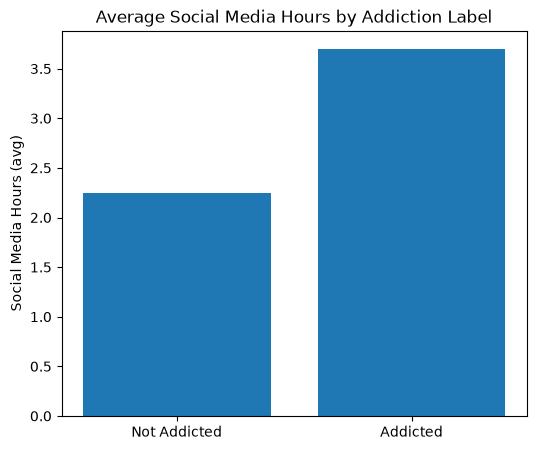

In [31]:
plt.figure(figsize=(6, 5))

plt.bar(
    ["Not Addicted", "Addicted"],
    [not_addicted_hours.mean(), addicted_hours.mean()]
)

plt.title("Average Social Media Hours by Addiction Label")
plt.ylabel("Social Media Hours (avg)")

plt.savefig("figures/fig07_social_media_by_addiction.png")
plt.show()

### Average Daily Hours by Addiction Label

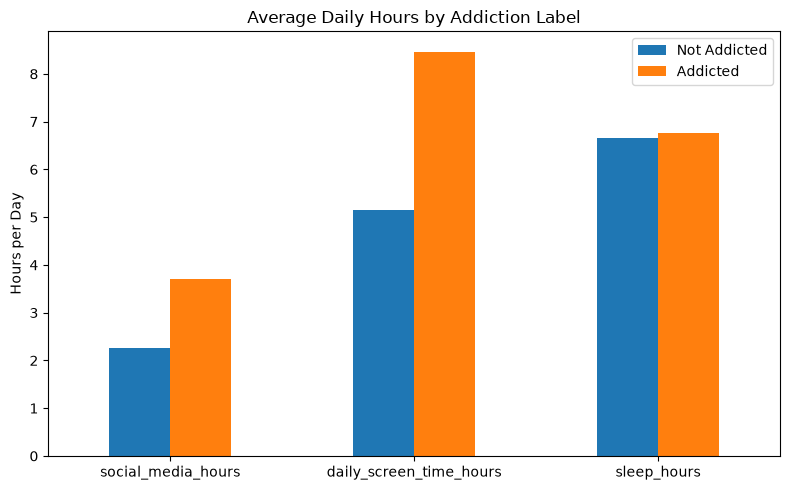

In [32]:
plot_means = addiction_group_means[
    ["social_media_hours", "daily_screen_time_hours", "sleep_hours"]
].T

plot_means.columns = ["Not Addicted", "Addicted"]

plot_means.plot(kind="bar", figsize=(8, 5))

plt.title("Average Daily Hours by Addiction Label")
plt.ylabel("Hours per Day")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("figures/fig08_addiction_group_means.png")
plt.show()

### Sleep Deficit and Digital Load

In [33]:
sleep_corr = phone_clean[
    [
        "Sleep_Deficit",
        "Digital_Load_Index",
        "daily_screen_time_hours",
        "social_media_hours"
    ]
].corr()

print(sleep_corr)

                         Sleep_Deficit  Digital_Load_Index  \
Sleep_Deficit                 1.000000           -0.013415   
Digital_Load_Index           -0.013415            1.000000   
daily_screen_time_hours      -0.015759            0.802173   
social_media_hours           -0.005861            0.492030   

                         daily_screen_time_hours  social_media_hours  
Sleep_Deficit                          -0.015759           -0.005861  
Digital_Load_Index                      0.802173            0.492030  
daily_screen_time_hours                 1.000000            0.010321  
social_media_hours                      0.010321            1.000000  


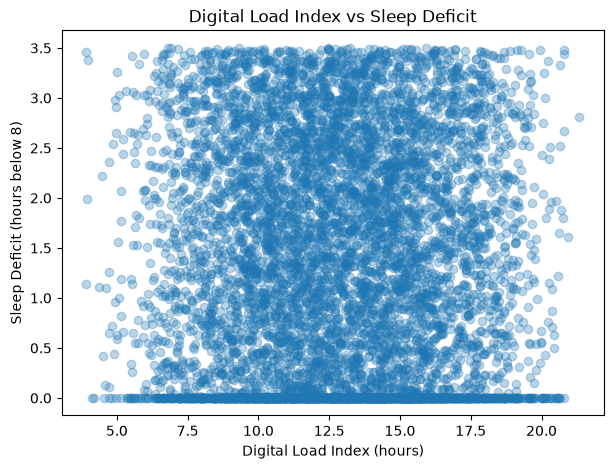

In [34]:
plt.figure(figsize=(7, 5))

plt.scatter(
    phone_clean["Digital_Load_Index"],
    phone_clean["Sleep_Deficit"],
    alpha=0.3
)

plt.title("Digital Load Index vs Sleep Deficit")
plt.xlabel("Digital Load Index (hours)")
plt.ylabel("Sleep Deficit (hours below 8)")

plt.savefig("figures/fig09_load_vs_sleep_deficit.png")
plt.show()

### Stress Level vs Screen Time (Phone Dataset)

In [35]:
stress_screen_means = phone_clean.groupby("stress_level")["daily_screen_time_hours"].mean()

print(stress_screen_means.sort_values(ascending=False))

stress_level
High      7.581359
Low       7.498761
Medium    7.415535
Name: daily_screen_time_hours, dtype: float64


### Test: Screen Time Across Stress Levels

In [36]:
stress_groups = [
    group["daily_screen_time_hours"].values
    for _, group in phone_clean.groupby("stress_level")
]

f_stat, f_pvalue = f_oneway(*stress_groups)
h_stat, h_pvalue = kruskal(*stress_groups)

print("ANOVA F:", f_stat, "p-value:", f_pvalue)
print("Kruskal-Wallis H:", h_stat, "p-value:", h_pvalue)

ANOVA F: 2.52277758287325 p-value: 0.08030454684261136
Kruskal-Wallis H: 4.994382750793309 p-value: 0.08231586863242682


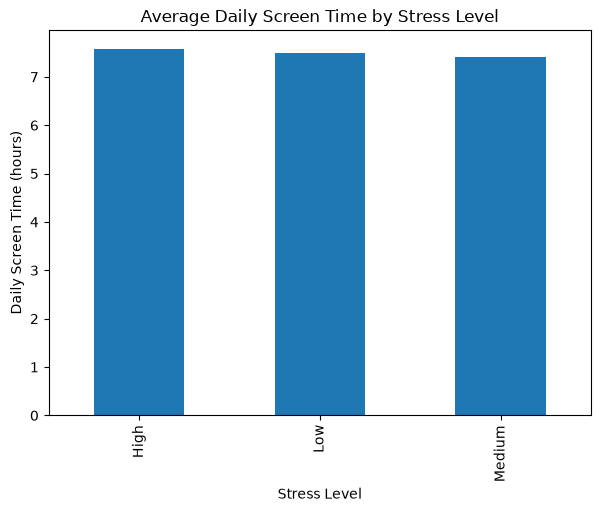

In [37]:
plt.figure(figsize=(7, 5))

stress_screen_means.sort_values(ascending=False).plot(kind="bar")

plt.title("Average Daily Screen Time by Stress Level")
plt.ylabel("Daily Screen Time (hours)")
plt.xlabel("Stress Level")

plt.savefig("figures/fig10_screen_by_stress.png")
plt.show()

### Digital Load Distribution (Descriptive Grouping, Not a Model)

In [38]:
def load_category(hours):
    if hours >= 10:
        return "High Digital Load"
    elif hours >= 5:
        return "Moderate Digital Load"
    else:
        return "Low Digital Load"

phone_clean["Digital_Load_Category"] = phone_clean["Digital_Load_Index"].apply(load_category)

print(phone_clean["Digital_Load_Category"].value_counts())

Digital_Load_Category
High Digital Load        5869
Moderate Digital Load    1604
Low Digital Load           27
Name: count, dtype: int64


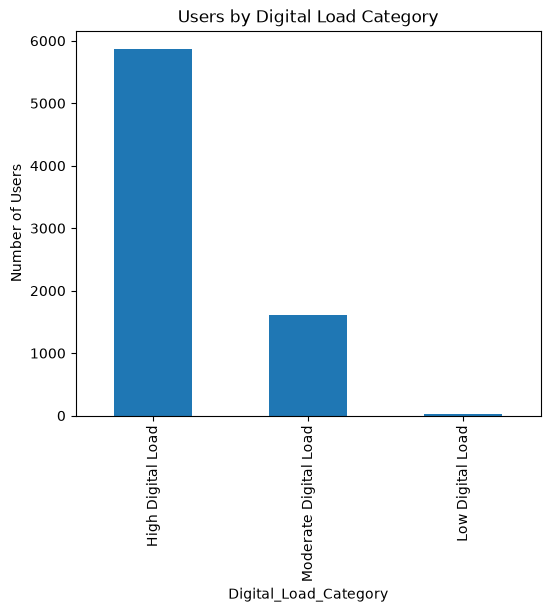

In [39]:
plt.figure(figsize=(6, 5))

phone_clean["Digital_Load_Category"].value_counts().plot(kind="bar")

plt.title("Users by Digital Load Category")
plt.ylabel("Number of Users")

plt.savefig("figures/fig11_digital_load_categories.png")
plt.show()

### Multiple Comparisons

In [40]:
# five research questions are tested, so a Bonferroni-adjusted threshold is also reported
n_tests = 5

print("Bonferroni-adjusted alpha:", 0.05 / n_tests)

Bonferroni-adjusted alpha: 0.01


### Research Summary

In [41]:
print("========== FocusLens Research Summary ==========")

print(f"Screen time vs cognitive score: r = {r_value:.3f}, 95% CI [{ci_low:.3f}, {ci_high:.3f}], p = {p_value:.4g}")
print(f"Spearman rho = {rho:.3f}")

print(
    f"Low vs high screen-time cognitive score: "
    f"{low_group.mean():.2f} vs {high_group.mean():.2f} "
    f"(t = {t_stat_screen:.2f}, d = {d_screen:.2f})"
)

print(
    f"Social media hours, addicted vs non-addicted: "
    f"{addicted_hours.mean():.2f} vs {not_addicted_hours.mean():.2f} "
    f"(t = {t_stat_addicted:.2f}, d = {d_addicted:.2f})"
)

print(f"Digital load vs sleep deficit: r = {sleep_corr.loc['Digital_Load_Index', 'Sleep_Deficit']:.3f}")
print(f"Screen time across stress levels: F = {f_stat:.2f}, p = {f_pvalue:.4f}")

print(
    "\nThese results are correlational, not causal - they describe a pattern in the data, "
    "not proof that short-form video usage causes attention loss."
)

========== FocusLens Research Summary ==========
Screen time vs cognitive score: r = -0.199, 95% CI [-0.205, -0.192], p = 0
Spearman rho = -0.190
Low vs high screen-time cognitive score: 62.14 vs 54.15 (t = 49.73, d = 0.35)
Social media hours, addicted vs non-addicted: 3.70 vs 2.25 (t = 46.88, d = 1.00)
Digital load vs sleep deficit: r = -0.013
Screen time across stress levels: F = 2.52, p = 0.0803

These results are correlational, not causal - they describe a pattern in the data, not proof that short-form video usage causes attention loss.


### Conclusion (توعوي / Awareness)

The numbers above show a small negative association between daily screen time and cognitive score,
a gap in cognitive score between low and high screen-time groups, and higher social media use among
users labeled as addicted. They show no meaningful relationship between digital load and sleep deficit,
or between stress level and screen time. The Data Realism Check also shows that the variables behave
like independent uniform random values, so these datasets are best treated as illustrative, not as
evidence about real people. Since none of the datasets log platform-level usage, the next step for a
stronger claim would be real short-video watch-time data or the EEG-based datasets.

هدف هذا التحليل توعوي: مساعدة القارئ على ربط عادات الاستخدام اليومية (وقت الشاشة، عدد الإشعارات،
ساعات السوشال ميديا) بمؤشرات الانتباه والتعب الذهني، دون الادعاء بعلاقة سببية مؤكدة.